# 2 · Calcitsäule: eine Gleichgewichtsfront, die mit der Strömung wandert

**Was Sie hier lernen**

- Advektion–Dispersion aller Elementsummen bei konstantem Darcy-Fluss
- ein reines **Gleichgewichts**problem (keine Kinetik): Lösungs- und Fällungsfronten
- die OGS-Regeln für die Umrechnung zwischen transportierten Konzentrationen und Knotenmengen (`hydrology='full'`)
- warum die Abweichungen zu OGS fast vollständig an einem Knoten liegen

## Das Problem

Eine 0,5 m lange Säule mit Calcit und inertem Füllstoff (OGS5GEMDEV `C/calcite_gems`, der klassische Benchmark
von Engesgaard & Kipp). Am linken Ende wird MgCl₂-Lösung eingeleitet. Calcit löst sich, Mg fällt in einem Band
direkt hinter der Lösungsfront als **Dolomit** aus, und der Dolomit wird wieder gelöst, sobald die Front vorbei ist.

$$\phi\,\frac{\partial c}{\partial t} + q\,\frac{\partial c}{\partial x}
 - \frac{\partial}{\partial x}\Big(\phi\,D\,\frac{\partial c}{\partial x}\Big) = 0,
\qquad \phi D = \phi\,\tau D_m + \alpha_L\,q$$

| Größe | Wert | OGS-Datei |
|---|---|---|
| Säule, Netz | 0,5 m, 100 Linienelemente | `calcite.msh` |
| Darcy-Fluss $q$ | 2,9984·10⁻⁶ m/s (Quelle bei x = 0, Fläche 1 m²) | `calcite.st` |
| Dispersivität $\alpha_L$ | 0,0067 m | `calcite.mmp` |
| molekulare Diffusion | 10⁻¹⁰ m²/s, Tortuosität 1 | `calcite.mcp` |
| Zeit | 210 × 100 s | `calcite.tim` |
| Anfangs-/Zuflusschemie | b-Gesamtvektoren (Säule, Zuflussknoten) | `calcite.ic` |
| Zuflusskonzentration | mol pro m³ Fluid, ohne Lösungsmittel Wasser | `calcite.bc` |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ufl

ROOT = next(p / 'GEMS_FEniCSx_OGS5_Template' for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'GEMS_FEniCSx_OGS5_Template').exists())
sys.path.insert(0, str(ROOT))
from ogs_io import read_msh, read_constant_blocks, read_gli, read_vtk
from fe_mesh import OGSMesh
from transport import Transport
from gems_ogs import OGSGEMS
from reactive_transport import run
from compare import error_table

CASE = ROOT / 'cases' / '1_calcite'
OGS = CASE / 'ogs_input'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})

## Netz, Chemie und Anfangszustand

Die Anfangsbedingungsdatei enthält **b-Gesamtvektoren pro m³ porösem Medium** — einen für die Säule und einen
für den Zuflussknoten `POINT0`. Die Randbedingungsdatei enthält die Zufluss**konzentrationen in mol pro m³ Fluid
ohne das Lösungsmittel Wasser** — eine andere Einheit, leicht zu verwechseln.

GEMS rechnet an jedem Knoten mit einer eigenen Engine und Warmstarts (`warm_start=True`), wie in der früheren
eigenständigen Reproduktion. Ein GEMS-Durchlauf, keine Volumennormierung.

In [2]:
points, cells, _, _ = read_msh(OGS / 'calcite.msh')
mesh = OGSMesh(points[:, :1], cells['line'], 'interval')
gli, _ = read_gli(OGS / 'calcite.gli')
inlet = mesh.nodes_where(lambda p: np.isclose(p[:, 0], gli['POINT0'][0]))

chem = OGSGEMS(CASE / 'gems' / 'BC-dat.lst', mesh.n_nodes, hydrology='full', min_porosity=1e-4,
               accept=(2, 6), retry=True, warm_start=True, boundary_nodes=inlet)
comps = [f'{i + 1}-{e}' for i, e in enumerate(chem.elements)]
b_init = np.zeros((mesh.n_nodes, chem.nIC))
c_inlet = np.zeros(chem.nIC)
for pcs, var, geo, val in read_constant_blocks(OGS / 'calcite.ic', '#INITIAL_CONDITION'):
    if var in comps:
        b_init[slice(None) if geo == 'DOMAIN' else inlet, comps.index(var)] = val
for pcs, var, geo, val in read_constant_blocks(OGS / 'calcite.bc', '#BOUNDARY_CONDITION'):
    if var in comps:
        c_inlet[comps.index(var)] = val
chem.init_from_bulk(b_init, normalize=False)
chem.c[inlet] = c_inlet

j = int(np.argmax(mesh.points[:, 0]))
display(pd.DataFrame({'b vector, column [mol/m³]': b_init[j], 'pore water c, column [mol/m³ water]': chem.c[j],
                      'inlet c (calcite.bc)': c_inlet}, index=chem.elements).style.format('{:.4g}'))
print(f'porosity {chem.phi[j]:.5f}, pH {chem.pH[j]:.3f}, calcite {chem.amounts("Cal")[j]:.4f} mol/m³')

,"b vector, column [mol/m³]","pore water c, column [mol/m³ water]",inlet c (calcite.bc)
C,0.1086,0.1224,9.97e-06
Ca,0.1086,0.1224,9.97e-06
Cl,6.381e-06,1.994e-05,3.988
H,3.542e+04,0.1661,0.0002701
Mg,3.191e-06,9.971e-06,1.994
O,1.771e+04,0.6497,0.02011
Sn,4.175e+04,0,0
Zz,0,-6.916e-17,1.036e-15


porosity 0.32000, pH 9.910, calcite 0.0695 mol/m³


## Transport und Lauf

Der Darcy-Fluss ist hier konstant und wird `Transport` als UFL-Vektor übergeben. Der Elementkoeffizient ist
$\phi_e\tau D_m$; die Dispersion $\alpha_L|q|$ fügt `Transport` selbst hinzu.

210 steps in 8.9 s; v t = 0.197 m


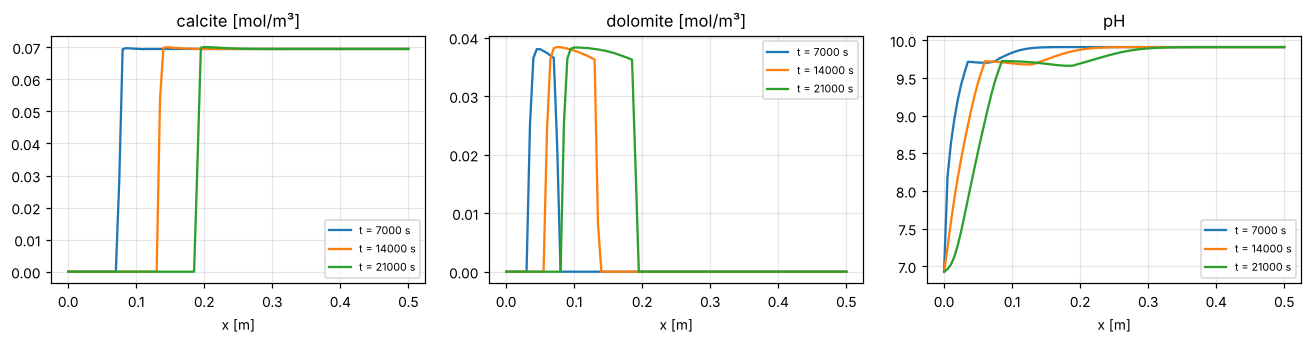

In [3]:
q, alpha_L, Dm, tau = 2.9984e-6, 0.0067, 1.0e-10, 1.0
tr = Transport(mesh, fixed_nodes=inlet, q=ufl.as_vector([q]), alpha_L=alpha_L)
tr.fixed_values = c_inlet
x = mesh.points[:, 0]
o = np.argsort(x)
snaps = {}

def prepare(step, t, dt):
    tr.phi_cell = chem.phi[mesh.cells].mean(1)
    tr.De_cell = tr.phi_cell * tau * Dm

def record(step, t, dt):
    if step % 70 == 0:
        snaps[t] = {s: chem.amounts(s)[o].copy() for s in ('Cal', 'Dis-Dol')} | {'pH': chem.pH[o].copy()}

log = run(chem, tr, [100.0] * 210, prepare=prepare, record=record, print_every=0)
print(f'{len(log)} steps in {log.wall_s.iloc[-1]:.1f} s; v t = {q / chem.phi.mean() * 21000:.3f} m')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for t_, s in snaps.items():
    for a, key in zip(ax, ('Cal', 'Dis-Dol', 'pH')):
        a.plot(x[o], s[key], label=f't = {t_:.0f} s')
for a, title in zip(ax, ('calcite [mol/m³]', 'dolomite [mol/m³]', 'pH')):
    a.set_title(title); a.set_xlabel('x [m]'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Vergleich mit OGS bei t = 21 000 s

quantity,ref_max,max_abs_diff,max_rel_diff
pH,9.91,2.31e-03,2.33e-04
NodePorosity,0.32,9.01e-08,2.82e-07
1-C,0.1432,7.24e-04,5.06e-03
2-Ca,0.3537,3.75e-03,1.06e-02
3-Cl,3.988,4.77e-05,1.20e-05
4-H,0.1747,7.88e-04,4.51e-03
5-Mg,2.044,4.46e-03,2.18e-03
6-O,0.6497,2.57e-03,3.95e-03
Cal,0.07007,3.53e-03,5.04e-02
Dis-Dol,0.03833,1.84e-03,4.80e-02


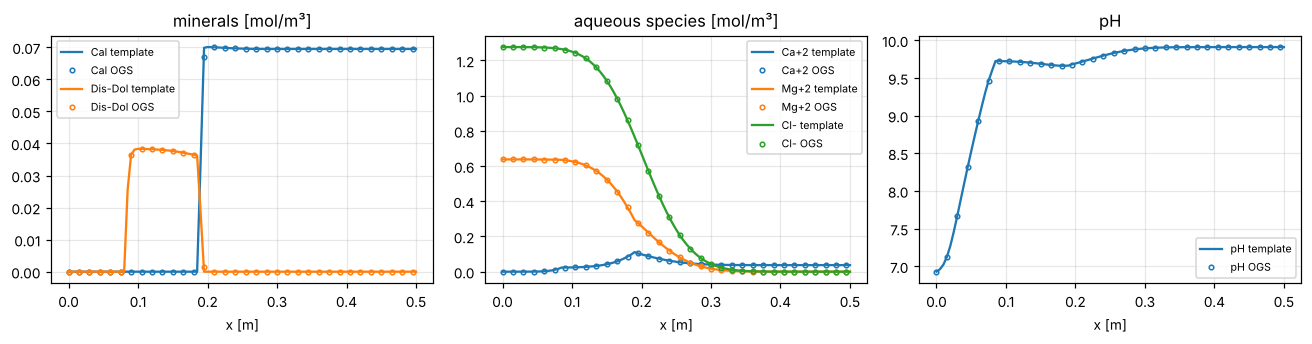

largest calcite difference at x = 0.190 m (the dissolution front); away from the front it is 9.5e-05 mol/m³


In [4]:
ref = read_vtk(CASE / 'reference' / 'calcite0210.vtk')
ro = np.argsort(ref['points'][:, 0])
ours = {'pH': chem.pH[o], 'NodePorosity': chem.phi[o], **{cn: chem.c[o, k] for k, cn in enumerate(comps[:6])},
        **{s: chem.amounts(s)[o] for s in ['Cal', 'Dis-Dol', 'Ca+2', 'Mg+2', 'Cl-']}}
refd = {k: ref['node__' + k][ro] for k in ours}
display(error_table(ours, refd).style.hide(axis='index').format({'ref_max': '{:.4g}', 'max_abs_diff': '{:.2e}', 'max_rel_diff': '{:.2e}'}))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, keys in zip(ax, (['Cal', 'Dis-Dol'], ['Ca+2', 'Mg+2', 'Cl-'], ['pH'])):
    for k in keys:
        a.plot(x[o], ours[k], label=f'{k} template')
        a.plot(x[o][::3], refd[k][::3], 'o', ms=3, mfc='none', color=a.lines[-1].get_color(), label=f'{k} OGS')
    a.set_xlabel('x [m]'); a.legend(fontsize=7)
ax[0].set_title('minerals [mol/m³]'); ax[1].set_title('aqueous species [mol/m³]'); ax[2].set_title('pH')
plt.tight_layout(); plt.show()
d = np.abs(ours['Cal'] - refd['Cal'])
print(f'largest calcite difference at x = {x[o][np.argmax(d)]:.3f} m (the dissolution front); '
      f'away from the front it is {np.sort(d)[-3]:.1e} mol/m³')

## Stolpersteine bei der Reproduktion

1. **Zwei Einheiten für dasselbe Element.** `calcite.ic` enthält Gesamtmengen pro m³ porösem Medium *einschließlich*
   Wasser und inertem Füllstoff (Sn); `calcite.bc` enthält Konzentrationen pro m³ Fluid *ohne* das Lösungsmittel
   Wasser. Der Zuflussknoten wird mit den `.ic`-Werten initialisiert, danach wird seine Konzentration durch die
   `.bc`-Werte überschrieben.
2. **Der restliche Fehler sitzt an einem Knoten.** Der Knoten an der Lösungsfront liegt genau zwischen „Calcit noch
   da“ und „Calcit weg“; er reagiert am stärksten auf kleine Unterschiede (GEMS-Version, Rundung). Calcit und Dolomit
   weichen dort um 5 % ab, überall sonst um weniger als 10⁻⁴ mol/m³.
3. **Nicht modelliert:** OGS macht aus dem Überschusswasser von GEMS eine Strömungsquelle; hier ist $q$ konstant. Die
   Mineralmengen liegen bei ~0,1 mol/m³, die Volumenänderung bei ~10⁻⁶ m³ — vernachlässigbar. `$MY_SMART_GEMS`
   (kaum veränderte Knoten überspringen) ist ebenfalls nicht umgesetzt.
4. **Dieselben Zahlen wie die eigenständige Reproduktion?** Bis auf $7\times10^{-4}$ (Dolomit) — GEMS antwortet auf eine
   Änderung der Eingabe in der 15. Stelle mit einer Änderung von etwa 10⁻⁶ in der Lösung; eine andere Summationsreihenfolge
   reicht dafür. Der Fehler gegenüber OGS bleibt gleich.

## Übungen

1. Halbieren Sie die Elementgröße (200 Elemente; Netz mit `OGSMesh(np.linspace(0, 0.5, 201)[:, None], ...)` erzeugen
   und die Anfangs-b-Vektoren selbst setzen). Wird der Fehler am Frontknoten kleiner?
2. Schalten Sie FEM-FCT ein (`Transport(..., fct=True)`). Ändert sich etwas, und warum (Gitter-Péclet-Zahl ansehen)?
3. Verwenden Sie `warm_start=False`. Vergleichen Sie Laufzeit und Ergebnisse.